In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import ConfusionMatrixDisplay

In [39]:
sns.set_style('whitegrid')
SEED = 42
np.random.seed(SEED)

In [5]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("gabrielsantello/advertisement-click-on-ad")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'advertisement-click-on-ad' dataset.
Path to dataset files: /kaggle/input/advertisement-click-on-ad


In [7]:
os.listdir(path)

['advertising.csv']

In [8]:
df = pd.read_csv(os.path.join(path, 'advertising.csv'))

In [58]:
num_cols = df.select_dtypes(include='number').columns.to_list()
cat_cols = df.select_dtypes(exclude='number').columns.to_list()

In [48]:
df.columns = df.columns.str.lower().str.replace(' ','_')

# Exploratory Data Analysis

In [49]:
df.head()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,ad_topic_line,city,male,country,timestamp,clicked_on_ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [61]:
df.describe()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,male,clicked_on_ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


In [62]:
num_feat = ['daily_time_spent_on_site', 'age', 'area_income', 'daily_internet_usage']

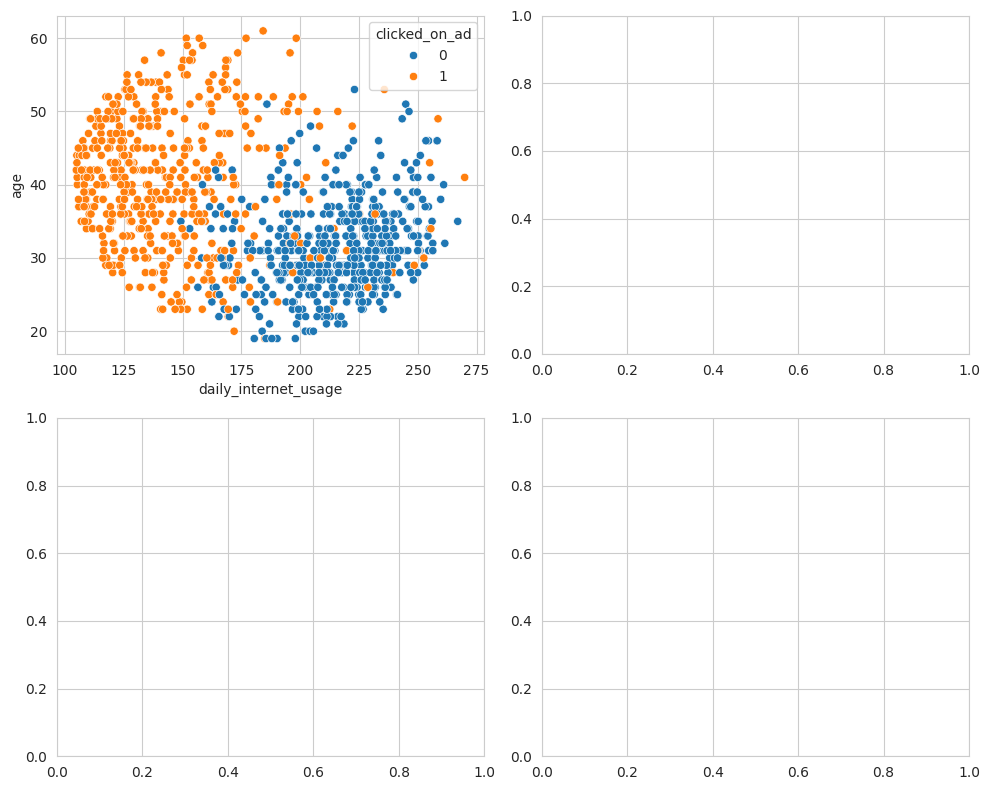

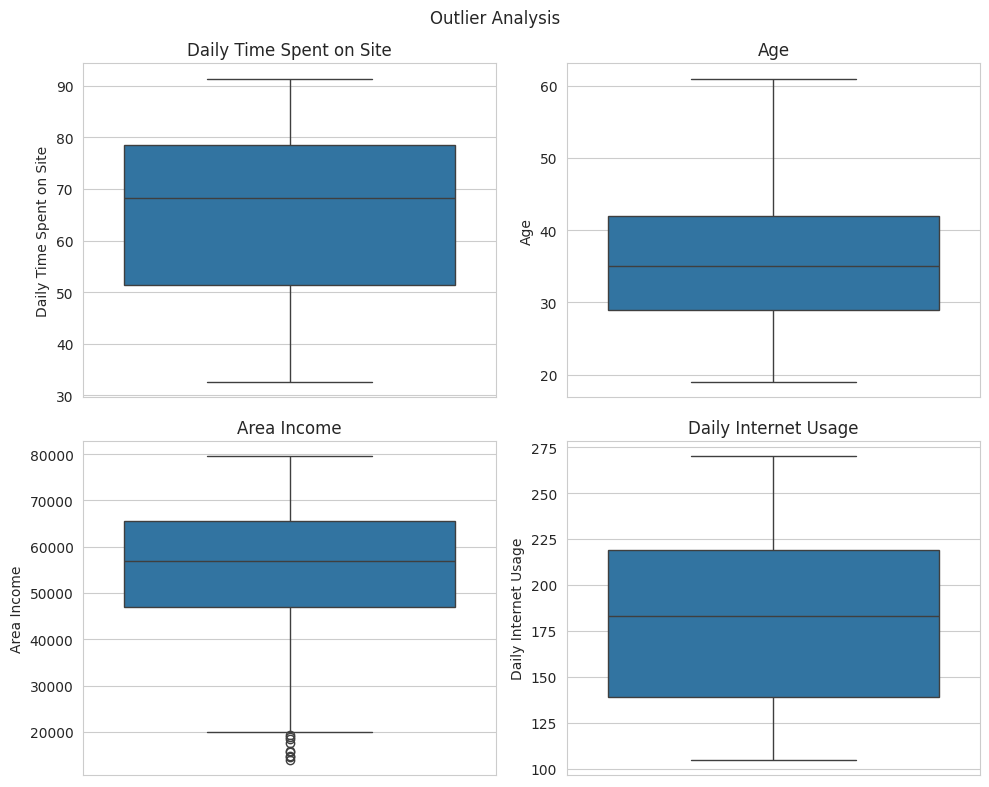

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10,8))
for feature, ax in zip(num_feat, axes.flatten()):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)
plt.suptitle('Outlier Analysis')
plt.tight_layout()
plt.show()

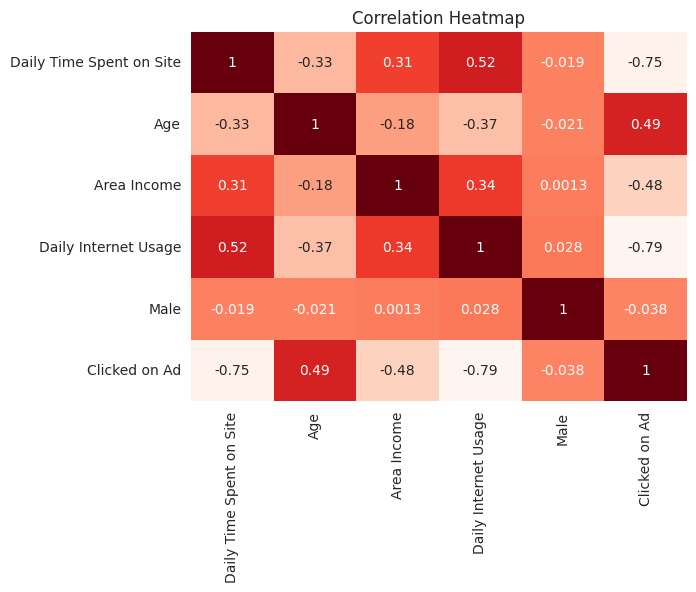

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cbar=False, cmap='Reds')
plt.title('Correlation Heatmap')
plt.show()

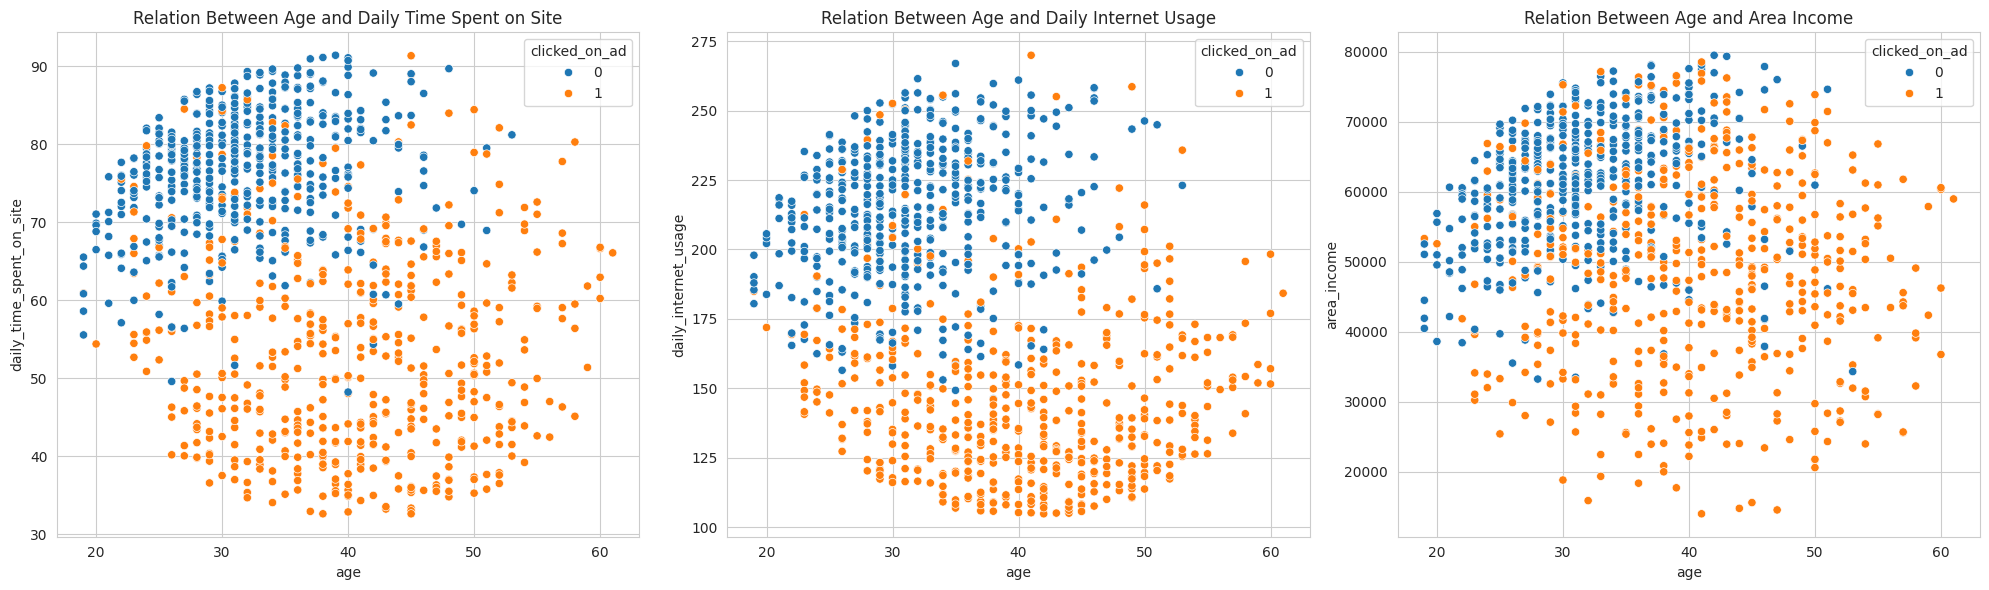

In [91]:
fig, axes = plt.subplots(1,3,figsize=(20,6))
sns.scatterplot(x='age', y='daily_time_spent_on_site', data=df, hue='clicked_on_ad', ax=axes[0])
axes[0].set_title('Relation Between Age and Daily Time Spent on Site')
sns.scatterplot(x='age', y='daily_internet_usage', data=df, hue='clicked_on_ad', ax=axes[1])
axes[1].set_title('Relation Between Age and Daily Internet Usage')
sns.scatterplot(x='age', y='area_income', data=df, hue='clicked_on_ad', ax=axes[2])
axes[2].set_title('Relation Between Age and Area Income')
plt.tight_layout()